In [1]:
from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt

import torch
from torch import Tensor, nn
from torch.utils.data import DataLoader, TensorDataset
import torch.nn.functional as F

import xarray as xr
import random
from dataclasses import dataclass
from typing import Iterable
import csv
from collections import defaultdict
from pathlib import Path


In [2]:
def set_seed(seed: int) -> None:
    """Seed supported random number generators for reproducible experiments."""
    if seed < 0:
        raise ValueError("seed must be non-negative")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

# Introduction

## Brief

1. Find some weather/climate data. Be
adventurous!

2. Get an LLM to help you write
PyTorch code that runs a
transformer (use time series data) or
an autoencoder (use gridded data)

3. Compare both against a suitable
baseline and evaluate performance

4. Submit your presentation and
Python notebook to the Google
Form.

5. Present in your group for 5 minutes


__We have chosen to use a variational autoencoder to investigate ocean states__

<h1>Data Preprocessing<h1>

In [3]:
pacific_centre_long = 200
pacific_centre_lat = -2

In [4]:
v_box_size = 128
h_box_size = 256

In [5]:
ds = xr.open_dataset('data/data.grib')


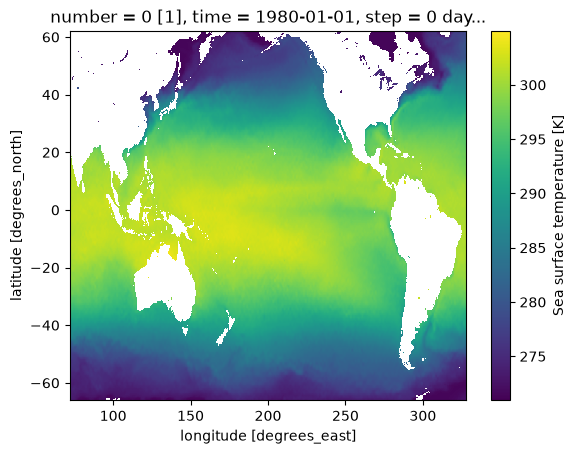

In [6]:
ds_pacific = ds.sel(latitude=slice(pacific_centre_lat + v_box_size/2, pacific_centre_lat - v_box_size/2), longitude=slice(pacific_centre_long - h_box_size/2, pacific_centre_long + h_box_size/2))
ds_pacific.sst[0].plot()

In [7]:
ds_pacific = ds_pacific.coarsen(latitude=2, longitude=4, boundary="trim").mean()

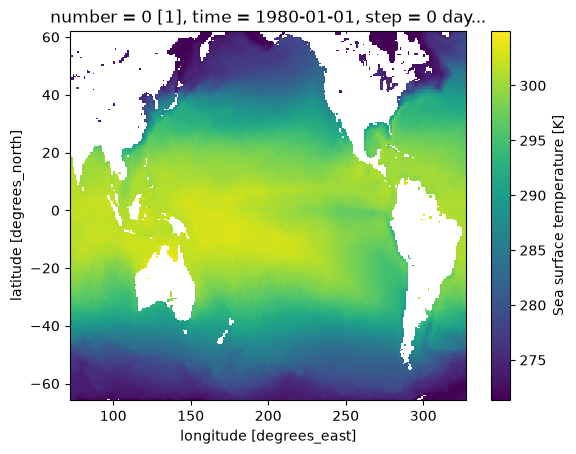

In [8]:
ds_pacific.sst[0].plot()

In [9]:
ds_mean = ds_pacific.sst.mean(dim=['latitude', 'longitude'])
ds_pacific_anomaly = ds_pacific - ds_mean

While cleaning the data I was unexpectedly reminded of climate change when observing the mean SST

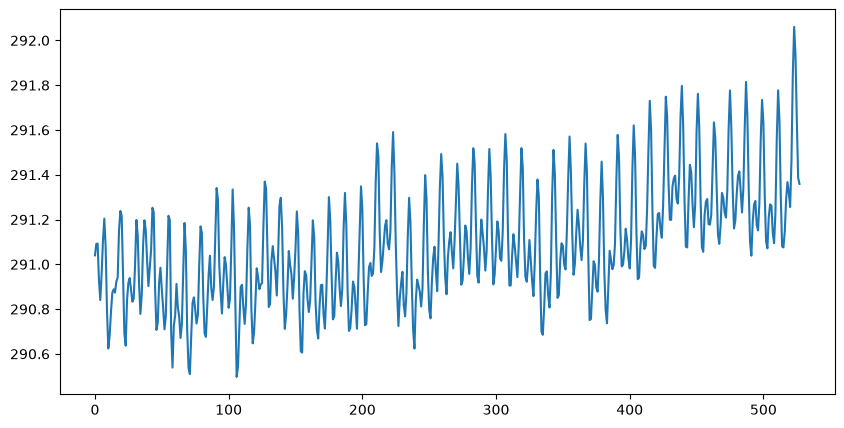

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ds_mean, label='Mean SST')

Text(0.5, 1.0, 'Pacific Sea Surface Temperature anomaly (SSTA) at time step 500')

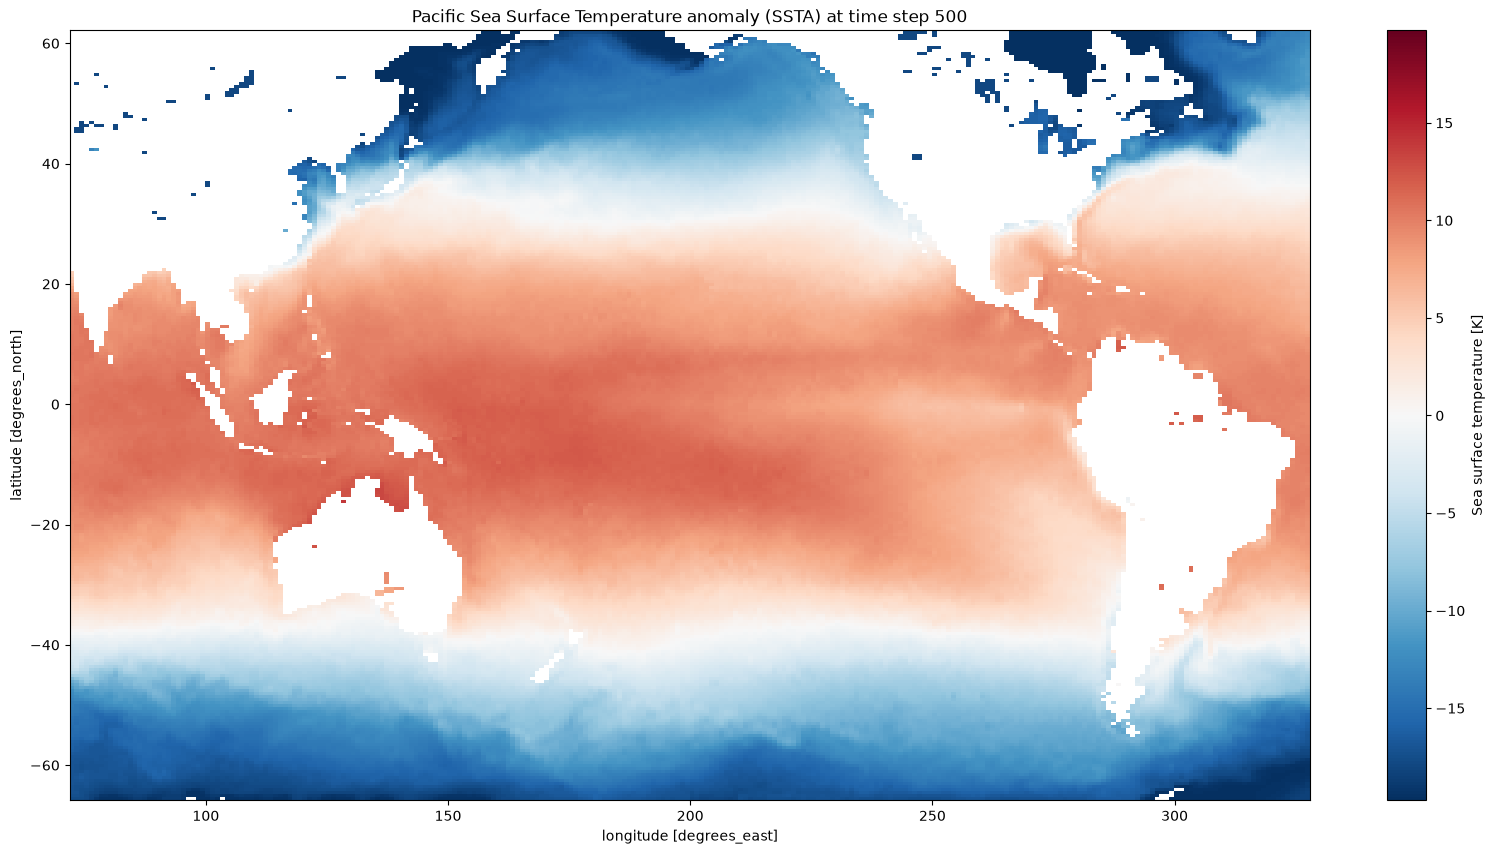

In [11]:
fig2, ax2 = plt.subplots(figsize=(20, 10))
ds_pacific_anomaly.sst[0].plot(ax=ax2)
ax2.set_title('Pacific Sea Surface Temperature anomaly (SSTA) at time step 500')

In [3]:
@dataclass
class Standardizer:
    """Training-set normalization parameters."""

    mean: float
    std: float

    def transform(self, values: np.ndarray) -> np.ndarray:
        return (values - self.mean) / self.std

    def inverse_transform(self, values: np.ndarray) -> np.ndarray:
        return values * self.std + self.mean


In [4]:
def prepare_sst(
    dataset: xr.Dataset,
    *,
    centre_longitude: float = 200,
    centre_latitude: float = -2,
    latitude_size: int = 128,
    longitude_size: int = 256,
    latitude_coarsen: int = 2,
    longitude_coarsen: int = 4,
) -> xr.DataArray:
    """Crop, coarsen, and remove the monthly SST climatology."""
    sst = dataset["sst"].sel(
        latitude=slice(
            centre_latitude + latitude_size / 2,
            centre_latitude - latitude_size / 2,
        ),
        longitude=slice(
            centre_longitude - longitude_size / 2,
            centre_longitude + longitude_size / 2,
        ),
    )
    sst = sst.coarsen(
        latitude=latitude_coarsen,
        longitude=longitude_coarsen,
        boundary="trim",
    ).mean()
    anomaly = sst.groupby("time.month") - sst.groupby("time.month").mean("time")
    return anomaly.transpose("time", "latitude", "longitude")


In [5]:
def make_dataloaders(
    data: xr.DataArray,
    *,
    validation_fraction: float = 0.2,
    batch_size: int = 16,
    seed: int = 0,
) -> tuple[DataLoader[tuple[Tensor]], DataLoader[tuple[Tensor]], Standardizer, int]:
    """Create chronological train/validation loaders and fit normalization on train."""
    if not 0 < validation_fraction < 1:
        raise ValueError("validation_fraction must be between 0 and 1")
    if data.dims != ("time", "latitude", "longitude"):
        raise ValueError("data must have time, latitude, and longitude dimensions")

    values = np.asarray(data.values, dtype=np.float32)
    split = int(values.shape[0] * (1 - validation_fraction))
    if split < 1 or split == values.shape[0]:
        raise ValueError("data must contain enough time steps for both splits")
    training_values = values[:split]
    finite_training_values = training_values[np.isfinite(training_values)]
    if finite_training_values.size == 0:
        raise ValueError("training data contains no finite SST values")
    mean = float(finite_training_values.mean())
    std = float(finite_training_values.std())
    if not np.isfinite(std) or std == 0:
        raise ValueError(
            "training data must have finite SST values with non-zero variation"
        )
    standardizer = Standardizer(mean, std)
    normalized = standardizer.transform(values)
    # Land cells are commonly NaN in SST products. Zero is the climatological
    # anomaly after standardization and keeps those cells from poisoning loss.
    normalized = np.nan_to_num(normalized, nan=0.0, posinf=0.0, neginf=0.0).astype(
        np.float32
    )
    tensors = torch.from_numpy(normalized[:, None])
    train = TensorDataset(tensors[:split])
    validation = TensorDataset(tensors[split:])
    generator = torch.Generator().manual_seed(seed)
    return (
        DataLoader(train, batch_size=batch_size, shuffle=True, generator=generator),
        DataLoader(validation, batch_size=batch_size, shuffle=False),
        standardizer,
        split,
    )

<h1>Variational Convolutional Autoencoder<h1>

In [6]:
class ConvVAE(nn.Module):
    """Convolutional VAE for 256 x 256 single-channel SST fields."""

    def __init__(self, latent_dim: int = 16) -> None:
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, 3, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.Conv2d(32, 64, 3, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 3, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, 3, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.Conv2d(256, 512, 3, stride=2, padding=1),
            nn.LeakyReLU(0.2),
        )
        self.mu = nn.Linear(512 * 8 * 8, latent_dim)
        self.logvar = nn.Linear(512 * 8 * 8, latent_dim)
        self.decoder_input = nn.Linear(latent_dim, 512 * 8 * 8)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(
                512, 256, 3, stride=2, padding=1, output_padding=1
            ),
            nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(
                256, 128, 3, stride=2, padding=1, output_padding=1
            ),
            nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(
                128, 64, 3, stride=2, padding=1, output_padding=1
            ),
            nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(
                64, 32, 3, stride=2, padding=1, output_padding=1
            ),
            nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(32, 1, 3, stride=2, padding=1, output_padding=1),
        )

    def encode(self, x: Tensor) -> tuple[Tensor, Tensor]:
        hidden = self.encoder(x).flatten(1)
        return self.mu(hidden), self.logvar(hidden)

    def decode(self, z: Tensor) -> Tensor:
        hidden = self.decoder_input(z).view(-1, 512, 8, 8)
        return self.decoder(hidden)

    def forward(self, x: Tensor) -> tuple[Tensor, Tensor, Tensor]:
        mu, logvar = self.encode(x)
        std = torch.exp(0.5 * logvar)
        z = mu + torch.randn_like(std) * std
        return self.decode(z), mu, logvar


In [14]:

def vae_loss(
    reconstruction: Tensor,
    target: Tensor,
    mu: Tensor,
    logvar: Tensor,
    *,
    beta: float = 1e-3,
) -> tuple[Tensor, Tensor, Tensor]:
    """Return total, reconstruction, and KL losses averaged per sample."""
    reconstruction_loss = nn.functional.mse_loss(reconstruction, target, reduction="mean")
    kl_loss = 0.5 * (mu.square() + logvar.exp() - 1 - logvar).sum(dim=1).mean()
    return reconstruction_loss + beta * kl_loss, reconstruction_loss, kl_loss


In [7]:
def _run_epoch(
    model: ConvVAE,
    loader: Iterable[tuple[Tensor]],
    device: torch.device,
    *,
    beta: float,
    optimizer: torch.optim.Optimizer | None,
) -> dict[str, float]:
    training = optimizer is not None
    model.train(training)
    totals = {"loss": 0.0, "reconstruction": 0.0, "kl": 0.0}
    samples = 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for (batch,) in loader:
            batch = batch.to(device)
            mu, logvar = model.encode(batch)
            if training:
                std = torch.exp(0.5 * logvar)
                latent = mu + torch.randn_like(std) * std
            else:
                latent = mu
            reconstruction = model.decode(latent)
            loss, reconstruction_loss, kl_loss = vae_loss(
                reconstruction, batch, mu, logvar, beta=beta
            )
            if optimizer is not None:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            count = batch.shape[0]
            samples += count
            totals["loss"] += loss.item() * count
            totals["reconstruction"] += reconstruction_loss.item() * count
            totals["kl"] += kl_loss.item() * count
    return {name: value / samples for name, value in totals.items()}

In [8]:
def train_conv_vae(
    model: ConvVAE,
    train_loader: DataLoader[tuple[Tensor]],
    validation_loader: DataLoader[tuple[Tensor]],
    *,
    epochs: int = 100,
    learning_rate: float = 1e-3,
    beta: float = 1e-3,
    weight_decay: float = 1e-5,
    patience: int = 15,
    min_delta: float = 1e-5,
    seed: int | None = None,
    device: str | torch.device | None = None,
) -> list[dict[str, float]]:
    """Train a VAE, stopping and restoring the best validation checkpoint."""
    if epochs < 1:
        raise ValueError("epochs must be positive")
    if patience < 1:
        raise ValueError("patience must be positive")
    if min_delta < 0:
        raise ValueError("min_delta must not be negative")
    if seed is not None:
        set_seed(seed)
    target_device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    model.to(target_device)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=learning_rate, weight_decay=weight_decay
    )
    history: list[dict[str, float]] = []
    best_validation_loss = float("inf")
    best_state = {
        name: parameter.detach().cpu().clone()
        for name, parameter in model.state_dict().items()
    }
    epochs_without_improvement = 0
    for epoch in range(epochs):
        train_metrics = _run_epoch(
            model, train_loader, target_device, beta=beta, optimizer=optimizer
        )
        validation_metrics = _run_epoch(
            model, validation_loader, target_device, beta=beta, optimizer=None
        )
        history.append(
            {
                "epoch": float(epoch + 1),
                **{f"train_{key}": value for key, value in train_metrics.items()},
                **{f"validation_{key}": value for key, value in validation_metrics.items()},
            }
        )
        if validation_metrics["loss"] < best_validation_loss - min_delta:
            best_validation_loss = validation_metrics["loss"]
            best_state = {
                name: parameter.detach().cpu().clone()
                for name, parameter in model.state_dict().items()
            }
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        print(
            f"epoch {epoch + 1:03d}/{epochs}: "
            f"train={train_metrics['loss']:.5f}, "
            f"validation={validation_metrics['loss']:.5f}"
        )
        if epochs_without_improvement >= patience:
            print(f"early stopping after {epoch + 1} epochs")
            break
    model.load_state_dict(best_state)
    return history

In [9]:
@torch.no_grad()
def encode_latents(
    model: ConvVAE,
    data: xr.DataArray,
    standardizer: Standardizer,
    *,
    batch_size: int = 32,
    device: str | torch.device | None = None,
) -> xr.Dataset:
    """Encode every SST field and return latent means indexed by timestamp."""
    target_device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    model.to(target_device)
    model.eval()
    values = standardizer.transform(np.asarray(data.values, dtype=np.float32))
    values = np.nan_to_num(values, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)
    loader = DataLoader(TensorDataset(torch.from_numpy(values[:, None])), batch_size=batch_size)
    latent_means: list[np.ndarray] = []
    for (batch,) in loader:
        mu, _ = model.encode(batch.to(target_device))
        latent_means.append(mu.cpu().numpy())
    latent = np.concatenate(latent_means, axis=0)
    coordinates = {"time": data.time, "latent": np.arange(model.latent_dim)}
    return xr.Dataset(
        {"latent_mean": (("time", "latent"), latent)},
        coords=coordinates,
    )

# Running the Model

In [10]:
BETA = 1e-2

In [11]:
seed = 42
set_seed(seed)
ds = xr.open_dataset("data/data.grib")
sst_anomaly = prepare_sst(ds)
train_loader, validation_loader, standardizer, split = make_dataloaders(
    sst_anomaly, batch_size=16, validation_fraction=0.2, seed=seed
)

In [12]:
values = sst_anomaly.values

print("Shape:", values.shape)
print("Finite values:", np.isfinite(values).sum())
print("NaN values:", np.isnan(values).sum())
print("Minimum:", np.nanmin(values))
print("Maximum:", np.nanmax(values))
print("Standard deviation:", np.nanstd(values))

Shape: (528, 256, 256)
Finite values: 27590112
NaN values: 7012896
Minimum: -13.294891
Maximum: 14.056061
Standard deviation: 0.66013217


In [15]:
model = ConvVAE(latent_dim=16)

history = train_conv_vae(
    model,
    train_loader,
    validation_loader,
    epochs=100,
    beta=BETA,
    learning_rate=3e-4,
    weight_decay=1e-4,
    patience=10,
    seed=seed,
)

latents = encode_latents(model, sst_anomaly, standardizer)

epoch 001/100: train=0.82895, validation=1.25941
epoch 002/100: train=0.75409, validation=1.01300
epoch 003/100: train=0.73350, validation=0.95447
epoch 004/100: train=0.67536, validation=0.87276
epoch 005/100: train=0.65158, validation=0.86900
epoch 006/100: train=0.63492, validation=0.85476
epoch 007/100: train=0.62227, validation=0.85217
epoch 008/100: train=0.60570, validation=0.83654
epoch 009/100: train=0.59594, validation=0.83353
epoch 010/100: train=0.58601, validation=0.80252
epoch 011/100: train=0.57767, validation=0.78645
epoch 012/100: train=0.57777, validation=0.79636
epoch 013/100: train=0.57536, validation=0.79754
epoch 014/100: train=0.56530, validation=0.78511
epoch 015/100: train=0.55603, validation=0.83540
epoch 016/100: train=0.55381, validation=0.79856
epoch 017/100: train=0.54823, validation=0.78638
epoch 018/100: train=0.54902, validation=0.77557
epoch 019/100: train=0.53842, validation=0.80015
epoch 020/100: train=0.53708, validation=0.78362
epoch 021/100: train

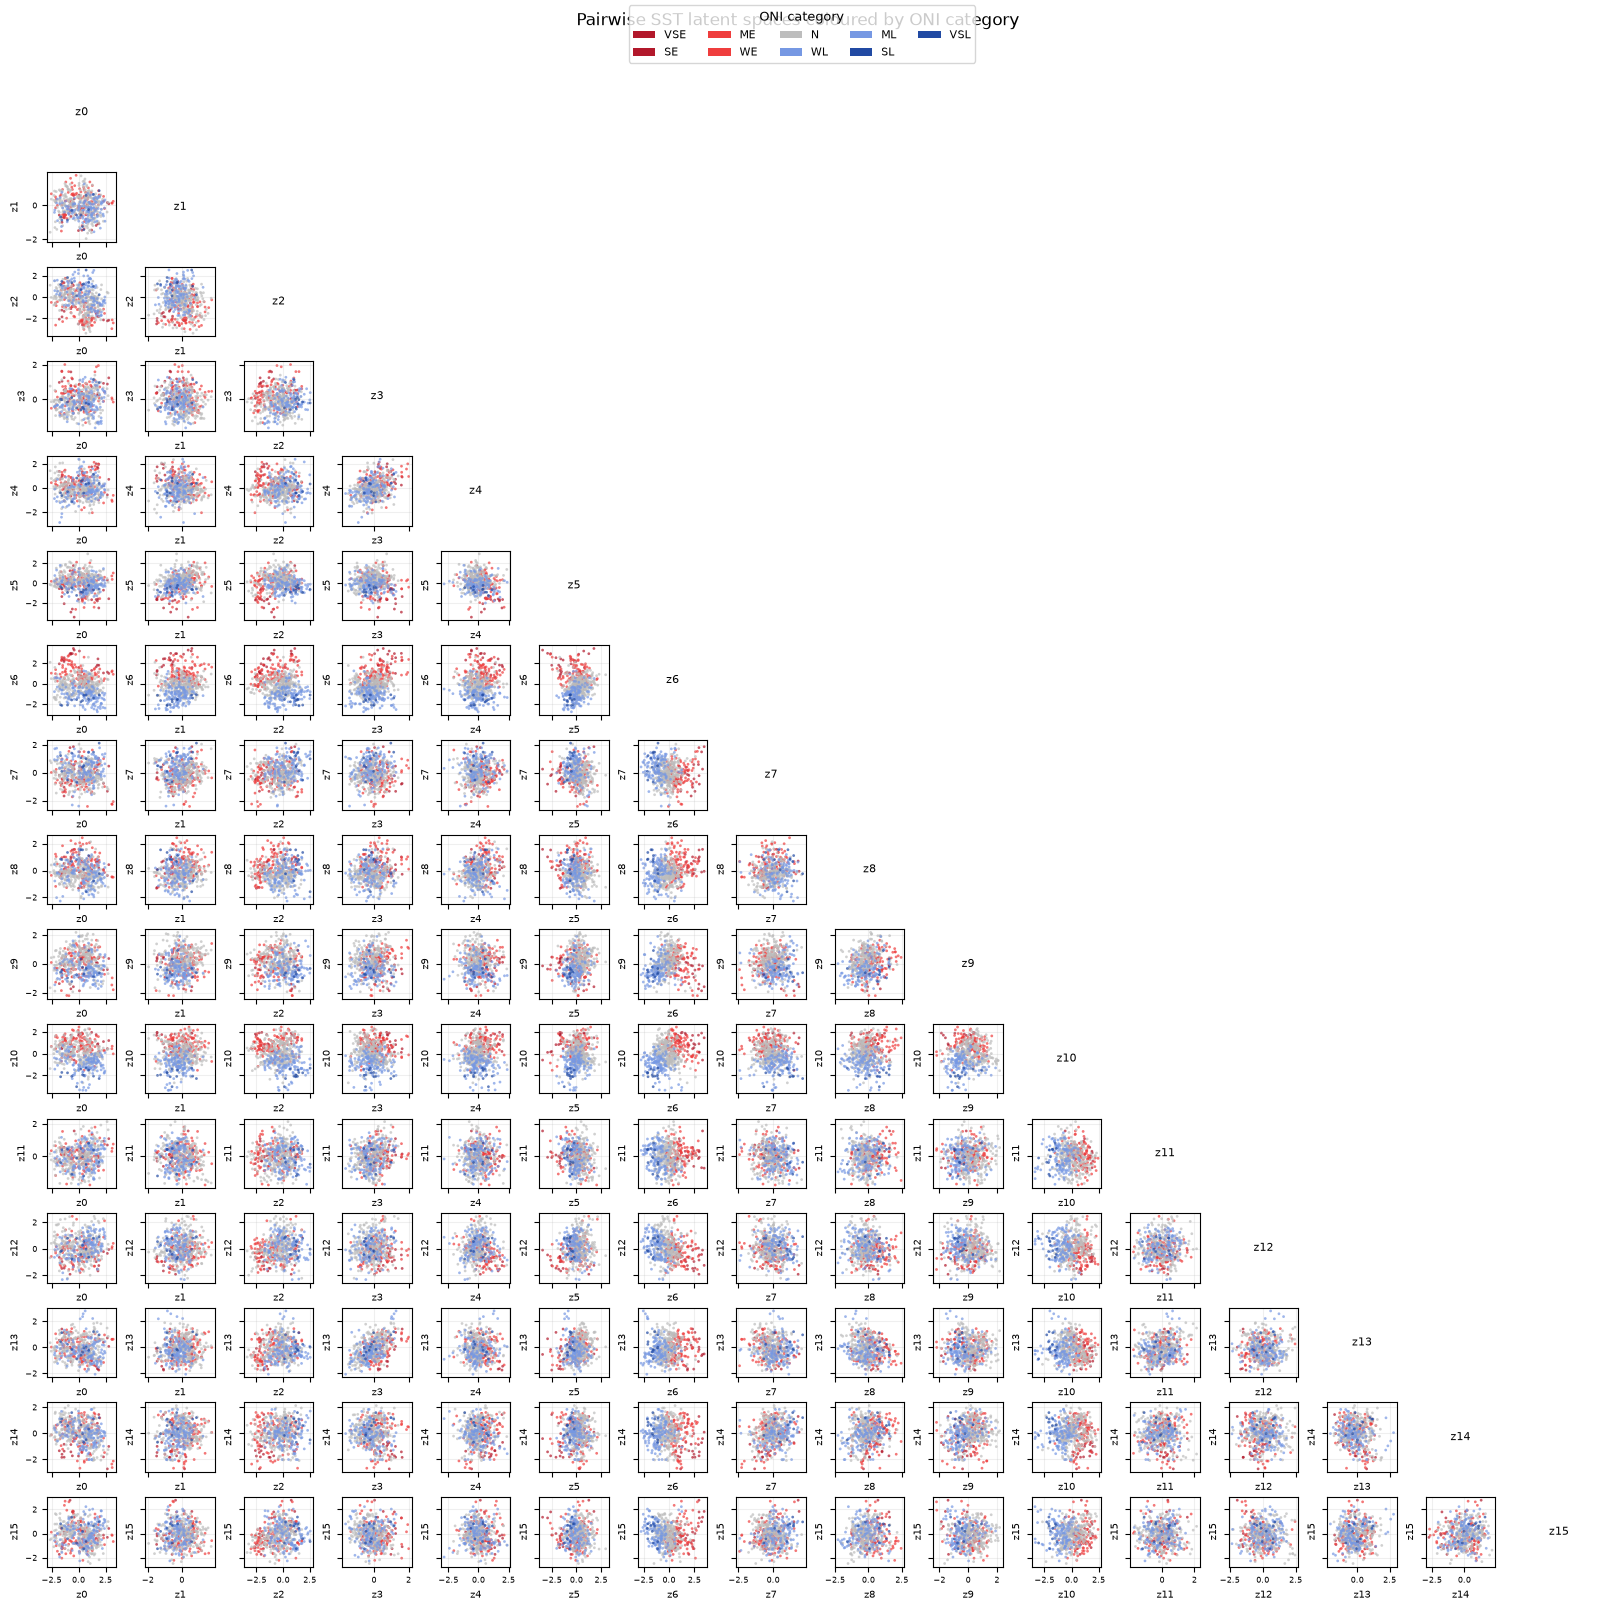

Matched 528 of 528 latent months to ONI categories


In [16]:


oni_by_date = {}
with Path("data/oni.csv").open(newline="") as oni_file:
    for row in csv.DictReader(oni_file):
        oni_by_date[row["date"]] = row["category"]

latent_dates = latents.time.dt.strftime("%Y-%m-%d").values
categories = np.array([oni_by_date.get(date, "Unlabelled") for date in latent_dates])
matched = categories != "Unlabelled"

category_colours = {
    "VSE": "#b2182b",
    "SE": "#b2182b",
    "ME": "#ef3d3d",
    "WE": "#ef3d3d",
    "N": "#bdbdbd",
    "WL": "#7698e3",
    "ML": "#7698e3",
    "SL": "#214aa3",
    "VSL": "#214aa3",
    
}

from itertools import combinations
from matplotlib.patches import Patch

latent_values = latents.latent_mean.values[matched]
latent_dimension = latent_values.shape[1]
fig, axes = plt.subplots(
    latent_dimension,
    latent_dimension,
    figsize=(16, 16),
    sharex="col",
    sharey="row",
    squeeze=False,
)

for row, column in combinations(range(latent_dimension), 2):
    ax = axes[column, row]
    for category, colour in category_colours.items():
        selected = categories[matched] == category
        ax.scatter(
            latent_values[selected, row],
            latent_values[selected, column],
            color=colour,
            s=4,
            alpha=0.7,
            edgecolors="none",
            rasterized=True,
        )
    ax.set_xlabel(f"z{row}", fontsize=7)
    ax.set_ylabel(f"z{column}", fontsize=7)
    ax.tick_params(labelsize=6)
    ax.grid(alpha=0.2)

for index in range(latent_dimension):
    axes[index, index].text(
        0.5,
        0.5,
        f"z{index}",
        ha="center",
        va="center",
        fontsize=8,
        transform=axes[index, index].transAxes,
    )
    axes[index, index].set_axis_off()

for row in range(latent_dimension):
    for column in range(row + 1, latent_dimension):
        axes[row, column].set_visible(False)

legend_handles = [
    Patch(facecolor=colour, label=category)
    for category, colour in category_colours.items()
]
fig.legend(
    handles=legend_handles,
    title="ONI category",
    loc="upper center",
    ncol=5,
    fontsize=8,
    title_fontsize=9,
)
fig.suptitle("Pairwise SST latent spaces coloured by ONI category", y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.97), pad=0.3)
plt.show()

print(f"Matched {matched.sum()} of {len(matched)} latent months to ONI categories")

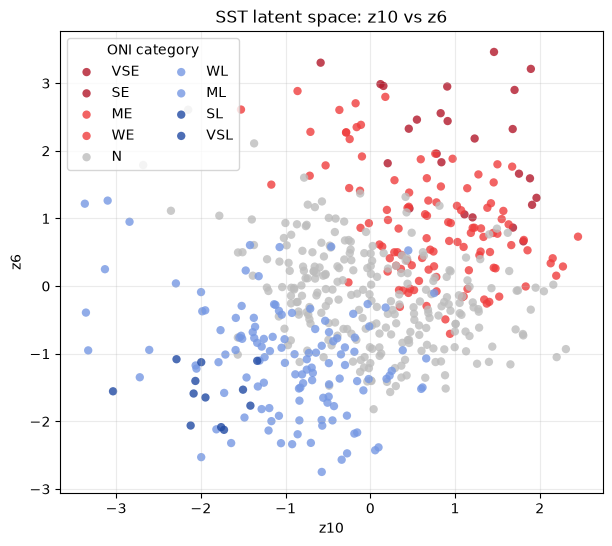

In [17]:
# Choose one pair of latent vectors to plot.
x_latent = 10    
y_latent = 6

if not (0 <= x_latent < latents.sizes["latent"]):
    raise ValueError(f"x_latent must be between 0 and {latents.sizes['latent'] - 1}")
if not (0 <= y_latent < latents.sizes["latent"]):
    raise ValueError(f"y_latent must be between 0 and {latents.sizes['latent'] - 1}")
if x_latent == y_latent:
    raise ValueError("x_latent and y_latent must be different")

fig, ax = plt.subplots(figsize=(7, 6))
for category, colour in category_colours.items():
    selected = matched & (categories == category)
    ax.scatter(
        latents.latent_mean.values[selected, x_latent],
        latents.latent_mean.values[selected, y_latent],
        color=colour,
        label=category,
        alpha=0.8,
        edgecolors="none",
    )

ax.set_xlabel(f"z{x_latent}")
ax.set_ylabel(f"z{y_latent}")
ax.set_title(f"SST latent space: z{x_latent} vs z{y_latent}")
ax.legend(title="ONI category", ncol=2)
ax.grid(alpha=0.25)
plt.show()


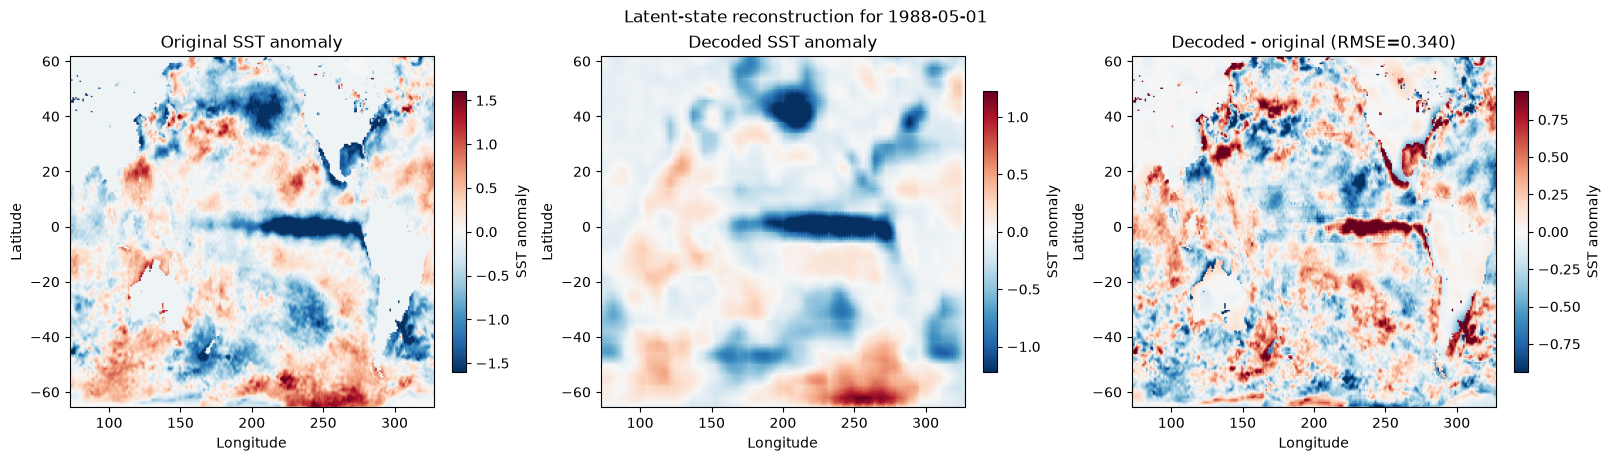

latent vector: [-0.389  0.428  1.465 -0.279 -0.87  -0.069  0.23   1.709 -0.052  1.283
 -1.47  -1.152 -0.945 -0.252  0.915  0.901]


In [19]:
# Decode one latent state and compare it with the original SST anomaly.
sample_index = 100
custom_latent = None  # Or set a length-16 array to decode a chosen latent state.

if not 0 <= sample_index < sst_anomaly.sizes["time"]:
    raise ValueError(
        f"sample_index must be between 0 and {sst_anomaly.sizes['time'] - 1}"
    )
if custom_latent is not None and len(custom_latent) != model.latent_dim:
    raise ValueError(f"custom_latent must contain {model.latent_dim} values")

device = next(model.parameters()).device
original_normalized = standardizer.transform(
    np.asarray(sst_anomaly.isel(time=sample_index).values, dtype=np.float32)
)
original_normalized = np.nan_to_num(
    original_normalized, nan=0.0, posinf=0.0, neginf=0.0
)
input_tensor = torch.from_numpy(original_normalized[None, None]).to(device)

model.eval()
with torch.no_grad():
    encoded_mu, _ = model.encode(input_tensor)
    latent_tensor = (
        torch.as_tensor(custom_latent, dtype=torch.float32, device=device)[None]
        if custom_latent is not None
        else encoded_mu
    )
    decoded_normalized = model.decode(latent_tensor)[0, 0].cpu().numpy()

original_anomaly = standardizer.inverse_transform(original_normalized)
decoded_anomaly = standardizer.inverse_transform(decoded_normalized)
error = decoded_anomaly - original_anomaly
date = str(sst_anomaly.time.isel(time=sample_index).values)[:10]
latent_values = latent_tensor[0].detach().cpu().numpy()
rmse = float(np.sqrt(np.nanmean(error**2)))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
image_extent = [
    float(sst_anomaly.longitude.min()),
    float(sst_anomaly.longitude.max()),
    float(sst_anomaly.latitude.min()),
    float(sst_anomaly.latitude.max()),
]
plots = [
    (original_anomaly, "Original SST anomaly"),
    (decoded_anomaly, "Decoded SST anomaly"),
    (error, f"Decoded - original (RMSE={rmse:.3f})"),
]
for axis, (image, title) in zip(axes, plots):
    limits = np.nanpercentile(np.abs(image), 98)
    im = axis.imshow(
        image,
        origin="upper",
        extent=image_extent,
        cmap="RdBu_r",
        vmin=-limits,
        vmax=limits,
        aspect="auto",
    )
    axis.set_title(title)
    axis.set_xlabel("Longitude")
    axis.set_ylabel("Latitude")
    fig.colorbar(im, ax=axis, shrink=0.8, label="SST anomaly")
fig.suptitle(f"Latent-state reconstruction for {date}")
plt.show()
print("latent vector:", np.round(latent_values, 3))
